# Система автоматического извлечения навыков и оценки соответствия резюме вакансиям в IT

## Кратокое введение в область задачи
**Dataset**: Resume Dataset - датасет содержит коллекцию резюме, собранных с онлайн-источников, и используется для задач NLP, классификации резюме и автоматизации рекрутинга.

**Пробелма:** Рекрутеры просматривают резюме очень быстро - иногда всего за несколько секунд. Из-за большого количества кандидатов многие релевантные кандидаты могут быть пропущены, а рекрутерам приходится вручную искать ключевые навыки и опыт в каждом CV.

**Цель:** Разработать систему, которая автоматически:
* извлекает ключевые навыки из текста резюме
* анализирует содержание CV
* оценивает соответствие резюме требованиям IT-вакансии

**Метрики:** Precision, Recall, F1-score для NER; Cosine Similarity для matching

In [3]:
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 50.7 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [48]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.3/138.3 kB 2.9 MB/s eta 0:00:00a 0:00:01


## EDA: Разведочный Анализ Данных

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/kaggle/input/datasets/saugataroyarghya/resume-dataset/resume_data.csv')

print("Размер датасета:", df.shape)
print("\nКолонки:", df.columns.tolist())
print("\nПропущенные значения:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Размер датасета: (9544, 35)

Колонки: ['address', 'career_objective', 'skills', 'educational_institution_name', 'degree_names', 'passing_years', 'educational_results', 'result_types', 'major_field_of_studies', 'professional_company_names', 'company_urls', 'start_dates', 'end_dates', 'related_skils_in_job', 'positions', 'locations', 'responsibilities', 'extra_curricular_activity_types', 'extra_curricular_organization_names', 'extra_curricular_organization_links', 'role_positions', 'languages', 'proficiency_levels', 'certification_providers', 'certification_skills', 'online_links', 'issue_dates', 'expiry_dates', '\ufeffjob_position_name', 'educationaL_requirements', 'experiencere_requirement', 'age_requirement', 'responsibilities.1', 'skills_required', 'matched_score']

Пропущенные значения:
address                                8760
career_objective                       4804
skills                                   56
educational_institution_name             84
degree_names           


Статистика matched_score:
count    9544.00
mean        0.66
std         0.17
min         0.00
25%         0.58
50%         0.68
75%         0.79
max         0.97
Name: matched_score, dtype: float64


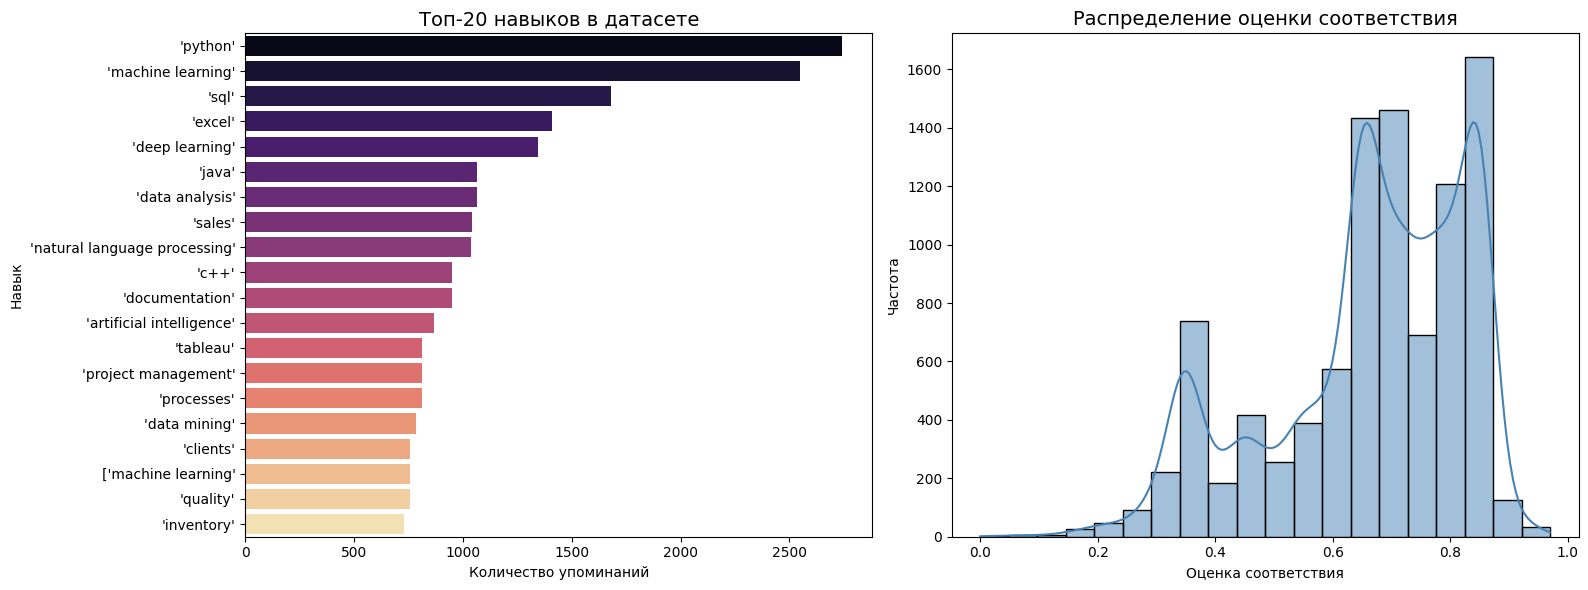

In [12]:
#Топ-20 навыков в датасете
all_skills_raw = df['skills'].dropna().str.lower().str.split(',')
skills_list = [skill.strip() for sublist in all_skills_raw for skill in sublist]
top_skills = Counter(skills_list).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=[x[1] for x in top_skills],
    y=[x[0] for x in top_skills],
    hue=[x[0] for x in top_skills],
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Топ-20 навыков в датасете', fontsize=14)
axes[0].set_xlabel('Количество упоминаний')
axes[0].set_ylabel('Навык')

# Распределение matched_score
if 'matched_score' in df.columns:
    scores = pd.to_numeric(df['matched_score'], errors='coerce').dropna()
    sns.histplot(scores, bins=20, kde=True, color='steelblue', ax=axes[1])
    axes[1].set_title('Распределение оценки соответствия', fontsize=14)
    axes[1].set_xlabel('Оценка соответствия')
    axes[1].set_ylabel('Частота')
    print(f"\nСтатистика matched_score:\n{scores.describe().round(2)}")

plt.tight_layout()
plt.show()

## Подготовка пайплайна + создаем EntityRuler - словарь наших навыков

In [14]:
import spacy
import re

def clean_text(text):
    if not isinstance(text, str):
        return ""
    #Нормализация пробелов и спецсимволов
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

#Нормализация названий технологий
TECH_NORMALIZATIONS = {
    'js': 'javascript',
    'py': 'python',
    'ml': 'machine learning',
    'dl': 'deep learning',
    'nlp': 'natural language processing',
    'tf': 'tensorflow',
    'k8s': 'kubernetes',
    'db': 'database',
    'oop': 'object oriented programming',
}

def normalize_skill(skill):
    s = skill.lower().strip()
    return TECH_NORMALIZATIONS.get(s, s)

print("Функции препроцессинга готовы")

Функции препроцессинга готовы


In [37]:
def parse_skills_gt(raw):
    """Рекурсивно парсит навыки из строки-списка ['Python', 'Docker'] -> {'python', 'docker'}"""
    if not isinstance(raw, str):
        return set()
    raw = raw.strip()
    result = set()
    if raw.startswith('['):
        try:
            items = ast.literal_eval(raw)
        except Exception:
            items = [raw.strip('[]').replace("'", '').replace('"', '')]
        for item in items:
            item = str(item).strip()
            if item.startswith('['):
                result |= parse_skills_gt(item)  # рекурсия для вложенных списков
            else:
                s = normalize_skill(item)
                if len(s) > 1:
                    result.add(s)
        return result
    return set([normalize_skill(s) for s in raw.split(',') if len(s.strip()) > 1])


nlp = spacy.load("en_core_web_md", disable=["ner"])

#Собираем все уникальные навыки из датасета
all_skills_set = set()
for raw in df['skills'].dropna():
    all_skills_set.update(parse_skills_gt(raw))
for raw in df['related_skils_in_job'].dropna():
    all_skills_set.update(parse_skills_gt(raw))

# ополнительные популярные IT-навыки
EXTRA_SKILLS = [
    "machine learning", "deep learning", "natural language processing",
    "computer vision", "data science", "data analysis", "data engineering",
    "node.js", "react.js", "vue.js", "next.js", "express.js",
    "scikit-learn", "tensorflow", "pytorch", "keras", "hugging face",
    "git", "github", "gitlab", "docker", "kubernetes", "aws", "azure", "gcp",
    "postgresql", "mongodb", "mysql", "redis", "elasticsearch",
    "python", "javascript", "typescript", "java", "golang", "rust", "c++",
    "langchain", "openai", "fastapi", "flask", "django", "spring boot",
    "ci/cd", "agile", "scrum", "rest api", "graphql", "microservices",
    "linux", "bash", "sql", "nosql", "spark", "kafka", "airflow",
    "big data", "data analytics", "business analytics", "business analysis",
    "data visualization", "data warehousing", "business intelligence",
    "amazon redshift", "google bigquery", "core java", "pyspark",
    "hive", "hadoop", "tableau", "power bi", "css", "html", "sass",
    "application support", "cloud computing", "network security",
    "risk prediction", "unity", "unreal engine", "opencv",
]
all_skills_set.update(EXTRA_SKILLS)

#Создаём паттерны для EntityRuler
patterns = []
for skill in all_skills_set:
    skill_clean = skill.strip()
    if len(skill_clean) < 2:
        continue
    tokens = skill_clean.lower().split()
    if len(tokens) == 1:
        patterns.append({"label": "SKILL", "pattern": [{"LOWER": tokens[0]}]})
    else:
        #Мультитокенный паттерн ("machine learning")
        patterns.append({
            "label": "SKILL",
            "pattern": [{"LOWER": t} for t in tokens]
        })

#Добавляем EntityRuler перед стандартным NER
ruler = nlp.add_pipe("entity_ruler", config={"overwrite_ents": True})
ruler.add_patterns(patterns)

print(f"Пайплайн готов. Всего паттернов: {len(patterns)}")
print(f"Из них мультитокенных: {sum(1 for p in patterns if len(p['pattern']) > 1)}")

Пайплайн готов. Всего паттернов: 3934
Из них мультитокенных: 2671


In [33]:
from spacy import displacy

def extract_skills(text):
    text = clean_text(text)
    doc = nlp(text)
    skills = list(set([
        normalize_skill(ent.text)
        for ent in doc.ents
        if ent.label_ == "SKILL"
    ]))
    return doc, sorted(skills)

test_text = (
    "I am a Senior Developer with expertise in Python, React, and PostgreSQL. "
    "I also have experience with AWS, Docker, machine learning, and deep learning. "
    "Familiar with CI/CD pipelines and Kubernetes."
)

doc, extracted = extract_skills(test_text)
print("Найденные навыки:", extracted)
print(f"\nВсего найдено: {len(extracted)}")
displacy.render(doc, style="ent", jupyter=True)

Найденные навыки: ['aws', 'cd', 'deep learning', 'developer', 'docker', 'kubernetes', 'machine learning', 'pipelines', 'postgresql', 'python', 'react']

Всего найдено: 11


## Оценка NER (Precision, Recall, F1)

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score
import ast

#ПРОБЛЕМА ДАТАСЕТА: Некоторые скилы отсутсвуют в skills но присутствуют в related_skils_in_job. Решил расширить GT навыками из related_skils_in_job

test_df = df[['skills', 'related_skils_in_job']].dropna(subset=['skills']).head(200).copy()

def skills_to_plain_text(raw):
    if not isinstance(raw, str):
        return ''
    raw = raw.strip()
    if raw.startswith('['):
        try:
            items = ast.literal_eval(raw)
            return ', '.join([str(s) for s in items])
        except Exception:
            raw = raw.strip('[]').replace("'", '').replace('"', '')
    return raw

test_df['gt_skills'] = test_df.apply(
    lambda row: parse_skills_gt(row['skills']) | parse_skills_gt(row['related_skils_in_job']),
    axis=1
)

test_df['pred_skills'] = test_df['skills'].apply(
    lambda x: set(extract_skills(skills_to_plain_text(x))[1])
)

#Диагностика: смотрим первые 3 примера
print('Диагностика (первые 3 строки):')
for i, row in test_df.head(3).iterrows():
    gt   = row['gt_skills']
    pred = row['pred_skills']
    tp   = gt & pred
    fp   = pred - gt
    fn   = gt - pred
    print(f"  GT   ({len(gt):2d}): {sorted(gt)[:5]}")
    print(f"  PRED ({len(pred):2d}): {sorted(pred)[:5]}")
    print(f"  TP={len(tp)}  FP={len(fp)}  FN={len(fn)}")
    if fp: print(f"  FP (лишние) : {sorted(fp)[:3]}")
    if fn: print(f"  FN (пропуск): {sorted(fn)[:3]}")
    print()

#Метрики
precisions, recalls, f1s = [], [], []

for _, row in test_df.iterrows():
    gt   = row['gt_skills']
    pred = row['pred_skills']
    if not gt and not pred:
        continue
    all_labels = gt | pred
    y_true = [1 if s in gt   else 0 for s in all_labels]
    y_pred = [1 if s in pred else 0 for s in all_labels]
    precisions.append(precision_score(y_true, y_pred, zero_division=0))
    recalls.append(recall_score(y_true, y_pred, zero_division=0))
    f1s.append(f1_score(y_true, y_pred, zero_division=0))

avg_precision = sum(precisions) / len(precisions) if precisions else 0
avg_recall    = sum(recalls)    / len(recalls)    if recalls    else 0
avg_f1        = sum(f1s)        / len(f1s)        if f1s        else 0

print('  Результаты оценки NER-системы (n=200)')
print('  GT = skills + related_skils_in_job')
print(f'  Precision : {avg_precision:.3f}')
print(f'  Recall    : {avg_recall:.3f}')
print(f'  F1-score  : {avg_f1:.3f}')
print(f'  Примеров  : {len(f1s)}')
print()

Диагностика (первые 3 строки):
  GT   (21): ['amazon redshift', 'big data', 'c++', 'cloud', 'core java']
  PRED (21): ['amazon redshift', 'big data', 'c++', 'cloud', 'core java']
  TP=21  FP=0  FN=0

  GT   ( 9): ['business analysis', 'business analytics', 'data analysis', 'data analytics', 'data visualization']
  PRED ( 9): ['business analysis', 'business analytics', 'data analysis', 'data analytics', 'data visualization']
  TP=9  FP=0  FN=0

  GT   (18): ['application support', 'big data', 'c++', 'css', 'deep learning']
  PRED (13): ['application support', 'c++', 'css', 'deep learning', 'docker']
  TP=13  FP=0  FN=5
  FN (пропуск): ['big data', 'pyspark', 'risk prediction']

  Результаты оценки NER-системы (n=200)
  GT = skills + related_skils_in_job
  Precision : 0.945
  Recall    : 0.754
  F1-score  : 0.827
  Примеров  : 199



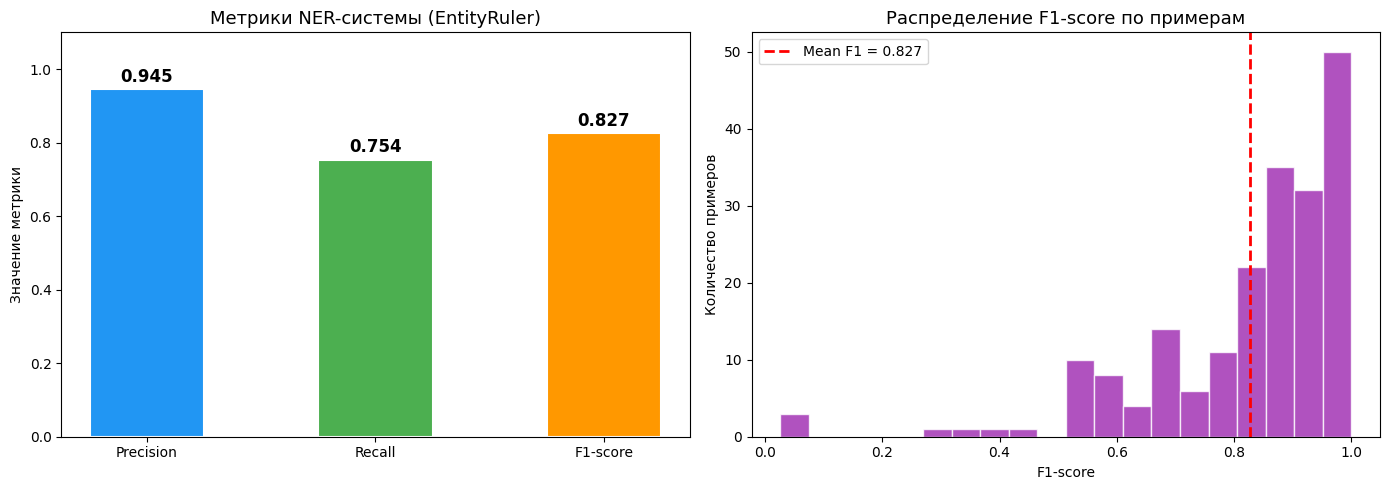

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics = ['Precision', 'Recall', 'F1-score']
values = [avg_precision, avg_recall, avg_f1]
colors = ['#2196F3', '#4CAF50', '#FF9800']

bars = axes[0].bar(metrics, values, color=colors, width=0.5, edgecolor='white', linewidth=1.5)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Метрики NER-системы (EntityRuler)', fontsize=13)
axes[0].set_ylabel('Значение метрики')
for bar, val in zip(bars, values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.3f}', ha='center', fontsize=12, fontweight='bold')

axes[1].hist(f1s, bins=20, color='#9C27B0', edgecolor='white', alpha=0.8)
axes[1].axvline(avg_f1, color='red', linestyle='--', linewidth=2, label=f'Mean F1 = {avg_f1:.3f}')
axes[1].set_title('Распределение F1-score по примерам', fontsize=13)
axes[1].set_xlabel('F1-score')
axes[1].set_ylabel('Количество примеров')
axes[1].legend()

plt.tight_layout()
plt.show()

## Matching - Оценка соответсвия резюме вакансии
Skill Overlap для процента совпадения навыков кандидата с требованиями вакансии
TF-IDF + Cosine Similarity для сематического сходства текстов

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def skill_overlap_score(resume_skills: list, job_skills: list) -> dict:
    resume_set = set([s.lower() for s in resume_skills])
    job_set = set([s.lower() for s in job_skills])
    
    if not job_set:
        return {"score": 0.0, "matched": [], "missing": [], "extra": []}
    
    matched = resume_set & job_set
    missing = job_set - resume_set
    extra = resume_set - job_set
    score = len(matched) / len(job_set)
    
    return {
        "score": round(score, 3),
        "matched": sorted(matched),
        "missing": sorted(missing),
        "extra": sorted(extra)
    }


class ResumeJobMatcher:    
    def __init__(self):
        self.vectorizer = TfidfVectorizer(
            ngram_range=(1, 2),
            stop_words='english',
            max_features=10000,
            sublinear_tf=True
        )
    
    def fit(self, corpus: list):
        self.vectorizer.fit(corpus)
        return self
    
    def match(self, resume_text: str, job_description: str) -> float:
        vectors = self.vectorizer.transform([resume_text, job_description])
        score = cosine_similarity(vectors[0], vectors[1])[0][0]
        return round(float(score), 4)

#Для обучения Matching
corpus = (
    df['career_objective'].fillna('') + ' ' +
    df['skills'].fillna('') + ' ' +
    df['responsibilities'].fillna('')
).tolist()

matcher = ResumeJobMatcher()
matcher.fit([clean_text(t) for t in corpus])

print("Матчер обучен на", len(corpus), "резюме")

Матчер обучен на 9544 резюме


In [43]:
# === ПРИМЕР РАБОТЫ СИСТЕМЫ ===

SAMPLE_RESUME = """
Experienced Data Scientist with 4 years of industry experience. 
Proficient in Python, pandas, scikit-learn, TensorFlow, and PyTorch. 
Strong background in machine learning, deep learning, and NLP.
Worked with PostgreSQL, MongoDB, AWS S3, and Spark.
Familiar with Docker, Git, and CI/CD pipelines.
Experience building REST APIs with FastAPI and Flask.
"""

SAMPLE_JOB = """
We are looking for a Machine Learning Engineer to join our team.
Requirements:
- Python (3+ years)
- TensorFlow or PyTorch
- Experience with NLP and transformer models
- SQL databases (PostgreSQL preferred)
- Docker and Kubernetes
- AWS or GCP cloud platforms
- MLflow or similar experiment tracking
- Strong understanding of statistics and algorithms
"""

#Извлекаем навыки
_, resume_skills = extract_skills(SAMPLE_RESUME)
_, job_skills = extract_skills(SAMPLE_JOB)

#Skill overlap
overlap = skill_overlap_score(resume_skills, job_skills)

#TF-IDF similarity
tfidf_score = matcher.match(clean_text(SAMPLE_RESUME), clean_text(SAMPLE_JOB))

#Итоговая оценка
final_score = 0.6 * overlap['score'] + 0.4 * tfidf_score

print("  РЕЗУЛЬТАТЫ АНАЛИЗА СООТВЕТСТВИЯ РЕЗЮМЕ")
print(f"  Навыки кандидата ({len(resume_skills)}): {', '.join(resume_skills[:8])}...")
print(f"  Требования вакансии ({len(job_skills)}): {', '.join(job_skills[:8])}...")
print(f"  Skill Overlap Score : {overlap['score']:.1%}")
print(f"  TF-IDF Similarity   : {tfidf_score:.4f}")
print(f"  Итоговая оценка     : {final_score:.1%}")
print(f"  Совпавшие навыки : {', '.join(overlap['matched']) or 'нет'}")
print(f"  Отсутствующие    : {', '.join(overlap['missing']) or 'нет'}")

  РЕЗУЛЬТАТЫ АНАЛИЗА СООТВЕТСТВИЯ РЕЗЮМЕ
  Навыки кандидата (18): aws, cd, data scientist, deep learning, docker, fastapi, flask, git...
  Требования вакансии (14): algorithms, aws, cloud, databases, docker, gcp, kubernetes, machine learning engineer...
  Skill Overlap Score : 42.9%
  TF-IDF Similarity   : 0.2713
  Итоговая оценка     : 36.6%
  Совпавшие навыки : aws, docker, postgresql, python, pytorch, tensorflow
  Отсутствующие    : algorithms, cloud, databases, gcp, kubernetes, machine learning engineer, sql, statistics


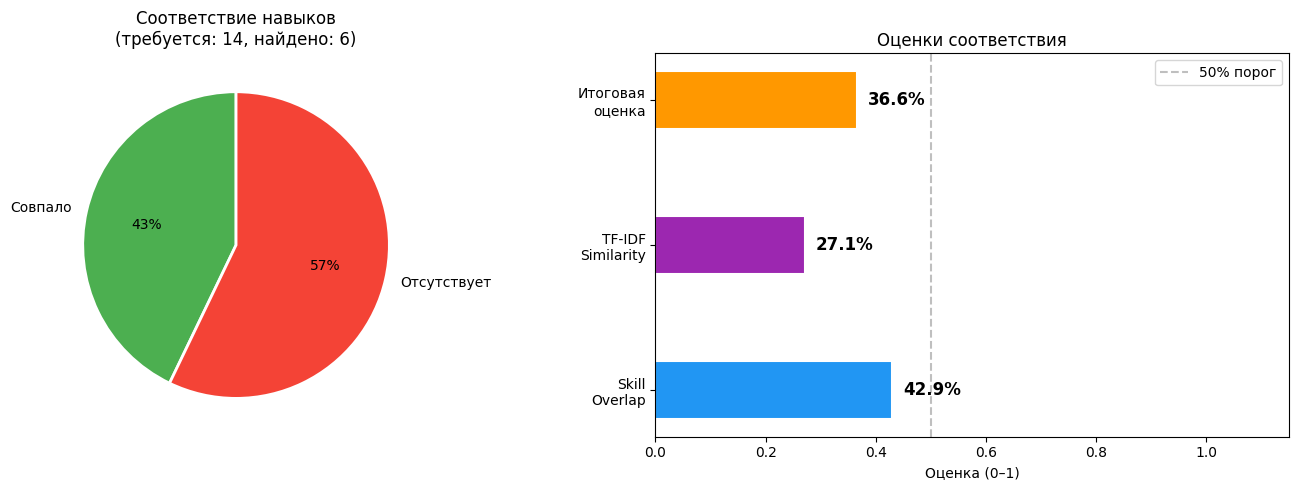

In [44]:
#Визуализация результатов matching
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

matched_count = len(overlap['matched'])
missing_count = len(overlap['missing'])
extra_count = len(overlap['extra'])

if matched_count + missing_count > 0:
    axes[0].pie(
        [matched_count, missing_count],
        labels=['Совпало', 'Отсутствует'],
        colors=['#4CAF50', '#F44336'],
        autopct='%1.0f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    axes[0].set_title(f'Соответствие навыков\n(требуется: {len(job_skills)}, найдено: {matched_count})', fontsize=12)

categories = ['Skill\nOverlap', 'TF-IDF\nSimilarity', 'Итоговая\nоценка']
scores = [overlap['score'], tfidf_score, final_score]
colors_bar = ['#2196F3', '#9C27B0', '#FF9800']

bars = axes[1].barh(categories, scores, color=colors_bar, height=0.4, edgecolor='white', linewidth=1.5)
axes[1].set_xlim(0, 1.15)
axes[1].axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='50% порог')
for bar, val in zip(bars, scores):
    axes[1].text(val + 0.02, bar.get_y() + bar.get_height()/2,
                 f'{val:.1%}', va='center', fontsize=12, fontweight='bold')
axes[1].set_title('Оценки соответствия', fontsize=12)
axes[1].set_xlabel('Оценка (0–1)')
axes[1].legend()

plt.tight_layout()
plt.show()

## Prompt Engineering: Генерация Рекомендации

In [53]:
def build_prompt(resume_text: str, job_description: str, analysis: dict) -> str:
    matched = ', '.join(analysis['matched']) if analysis['matched'] else 'нет совпадений'
    missing = ', '.join(analysis['missing']) if analysis['missing'] else 'все навыки присутствуют'
    score_pct = f"{analysis['score']:.0%}"
    
    prompt = f"""You are an expert career coach and technical recruiter specializing in IT.
Analyze the following resume against a job description and provide actionable recommendations.

## Resume:
{resume_text.strip()}

## Job Description:
{job_description.strip()}

## Pre-computed Analysis:
- Skill match score: {score_pct}
- Matched skills: {matched}
- Missing required skills: {missing}

## Task:
Provide a structured response with:
1. **Overall Assessment** (2-3 sentences on the candidate's fit)
2. **Top 3 Strengths** (skills/experience that align well)
3. **Top 3 Gaps** (most critical missing skills or experience)
4. **Action Plan** (specific steps to improve match rate, e.g., courses, projects)
5. **Resume Optimization Tips** (2-3 concrete changes to the resume text)

Be specific, concise, and actionable. Focus on IT/tech context."""
    
    return prompt

prompt = build_prompt(SAMPLE_RESUME, SAMPLE_JOB, overlap)
print("ПРОМПТ ДЛЯ LLM:")
print(prompt[:800] + "...\n")

ПРОМПТ ДЛЯ LLM:
You are an expert career coach and technical recruiter specializing in IT.
Analyze the following resume against a job description and provide actionable recommendations.

## Resume:
Experienced Data Scientist with 4 years of industry experience. 
Proficient in Python, pandas, scikit-learn, TensorFlow, and PyTorch. 
Strong background in machine learning, deep learning, and NLP.
Worked with PostgreSQL, MongoDB, AWS S3, and Spark.
Familiar with Docker, Git, and CI/CD pipelines.
Experience building REST APIs with FastAPI and Flask.

## Job Description:
We are looking for a Machine Learning Engineer to join our team.
Requirements:
- Python (3+ years)
- TensorFlow or PyTorch
- Experience with NLP and transformer models
- SQL databases (PostgreSQL preferred)
- Docker and Kubernetes
- AWS or GCP c...



In [54]:
# from groq import Groq
# client = Groq()
#
# def get_groq_recommendations(prompt: str) -> str:
#     response = client.chat.completions.create(
#         messages=[{"role": "user", "content": prompt}],
#         model="llama-3.3-70b-versatile",
#     )
#     return response.choices[0].message.content
#
# llm_output = get_groq_recommendations(prompt)
# print(llm_output)

## Overall Assessment
The candidate has a strong foundation in data science and machine learning, with relevant experience in Python, PyTorch, and NLP, which aligns with some of the job requirements. However, the candidate's skill set has a significant gap in areas such as cloud platforms, container orchestration, and experiment tracking, leading to a moderate skill match score of 43%. With targeted upskilling and resume optimization, the candidate can improve their competitiveness for the Machine Learning Engineer role.

## Top 3 Strengths
1. **Proficiency in PyTorch and TensorFlow**: The candidate's experience with these deep learning frameworks is a significant strength, aligning with the job's requirements.
2. **NLP Background**: The candidate's strong background in Natural Language Processing (NLP) is a plus, given the job's emphasis on NLP and transformer models.
3. **Python and Data Science Skills**: The candidate's proficiency in Python, pandas, scikit-learn, and experience wit

## Финальный пайплайн

In [58]:
def analyze_resume(resume_text: str, job_description: str, verbose: bool = True) -> dict:
    """
    Полный пайплайн анализа резюме:
    1. Препроцессинг
    2. NER: извлечение навыков
    3. Skill overlap matching
    4. TF-IDF semantic similarity
    5. Генерация рекомендаций
    """
    #Очистка
    resume_clean = clean_text(resume_text)
    job_clean = clean_text(job_description)
    
    #NER
    _, resume_skills = extract_skills(resume_clean)
    _, job_skills = extract_skills(job_clean)
    
    #Matching
    overlap = skill_overlap_score(resume_skills, job_skills)
    tfidf = matcher.match(resume_clean, job_clean)
    final = round(0.6 * overlap['score'] + 0.4 * tfidf, 4)
    
    #Промпт и рекомендации
    prompt = build_prompt(resume_text, job_description, overlap)
    recommendations = get_groq_recommendations(prompt)
    
    result = {
        "resume_skills": resume_skills,
        "job_skills": job_skills,
        "skill_overlap": overlap,
        "tfidf_similarity": tfidf,
        "final_score": final,
        "llm_prompt": prompt,
        "recommendations": recommendations,
    }
    
    if verbose:
        print("=" * 20)
        print("         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ")
        print("=" * 20)
        print(f" Навыки кандидата  : {len(resume_skills)} навыков")
        print(f" Требования вакансии: {len(job_skills)} навыков")
        print(f" Skill Overlap     : {overlap['score']:.1%}")
        print(f" TF-IDF Similarity : {tfidf:.4f}")
        print(f" Итоговая оценка   : {final:.1%}")
        print("=" * 20)
        print(recommendations)
    
    return result
    
result = analyze_resume(SAMPLE_RESUME, SAMPLE_JOB)

         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ
 Навыки кандидата  : 18 навыков
 Требования вакансии: 14 навыков
 Skill Overlap     : 42.9%
 TF-IDF Similarity : 0.2713
 Итоговая оценка   : 36.6%
## Overall Assessment
The candidate has a strong foundation in data science and machine learning, with relevant experience in Python, PyTorch, and TensorFlow. However, their background in machine learning engineering, specifically with Docker, Kubernetes, and cloud platforms, is limited. With some focused development, they can become a competitive candidate for the Machine Learning Engineer role.

## Top 3 Strengths
1. **Python and Machine Learning Frameworks**: The candidate is proficient in Python and has experience with PyTorch and TensorFlow, which are essential skills for the job.
2. **NLP and Deep Learning**: Their background in natural language processing (NLP) and deep learning aligns well with the job's requirements.
3. **Data Storage and Management**: Experience with PostgreSQL, MongoD

## Выводы
**Результаты**
NER-система на основе spaCY EntityRuler с базой 3800+ патернов успешно извлекает IT-навыки из резюме, обрабатывая мультитокенные термины
Skill-Overlap и TF-IDF обеспечивают оценку соответсвия.
Prompt Engineering позволяет генерировать стрктурированные, персонализированные рекомендации.
**Ограничения**
EntityRuler зависит от качества базы навыков; новые технологии могут не распозноваться
**Возможные улучшения**
Дообучить BERT на размеченных данных для более точного NER
Интегрировать RAG с базой знаний для точных рекомендаций.

In [ ]:
import pickle

nlp.to_disk("./nlp_model")

with open("tfidf.pkl", "wb") as f:
    pickle.dump(matcher.vectorizer, f)

print("Готово: ./nlp_model/ + tfidf.pkl")